In [1]:
!pip install -q torch torchvision matplotlib seaborn scikit-learn pandas

Import libraries

In [14]:
import os
import zipfile
import torch
import torch.nn as nn
import torchvision
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report

Download the actual dataset

In [15]:
!wget -O FIRE-SMOKE-DATASET.zip https://github.com/DeepQuestAI/Fire-Smoke-Dataset/releases/download/v1/FIRE-SMOKE-DATASET.zip

--2026-11-23 09:37:38--  https://github.com/DeepQuestAI/Fire-Smoke-Dataset/releases/download/v1/FIRE-SMOKE-DATASET.zip
Resolving github.com (github.com)... 140.82.113.3
Connecting to github.com (github.com)|140.82.113.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/193940929/09220a00-9842-11e9-8756-2d8df8631bb5?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-23T10%3A20%3A12Z&rscd=attachment%3B+filename%3DFIRE-SMOKE-DATASET.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-11-23T09%3A19%3A27Z&ske=2026-11-23T10%3A20%3A12Z&sks=b&skv=2018-11-09&sig=jKy6z2LJxQxKEve0gcA9CqlTX%2BtzpdnvtSsWI7Sc1c8%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5NTQzMDI1OCwibmJmIjoxNzk1NDI2NjU4LCJwYXRoIjoicmVsZWFzZWF

Extract dataset

In [16]:
with zipfile.ZipFile("FIRE-SMOKE-DATASET.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully!")

Dataset extracted successfully!


Check dataset folders

In [17]:
train_data_dir = "/content/FIRE-SMOKE-DATASET/Train"
test_data_dir = "/content/FIRE-SMOKE-DATASET/Test"

print("Training folders:", os.listdir(train_data_dir))
print("Testing folders:", os.listdir(test_data_dir))

Training folders: ['Fire', 'Smoke', 'Neutral']
Testing folders: ['Fire', 'Smoke', 'Neutral']


Define image transformations

In [18]:
transforms_train = transforms.Compose([
    transforms.Resize(225),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

transforms_test = transforms.Compose([
    transforms.Resize(225),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

Load training and testing datasets

In [19]:
batch_sizes = 64

train_data = datasets.ImageFolder(
    root=train_data_dir,
    transform=transforms_train
)

test_data = datasets.ImageFolder(
    root=test_data_dir,
    transform=transforms_test
)

print("Classes:", train_data.classes)
print("Training images:", len(train_data))
print("Testing images:", len(test_data))

Classes: ['Fire', 'Neutral', 'Smoke']
Training images: 2700
Testing images: 300


Create DataLoaders

In [20]:
train_data_loader = DataLoader(
    train_data,
    batch_size=batch_sizes,
    shuffle=True
)

test_data_loader = DataLoader(
    test_data,
    batch_size=batch_sizes,
    shuffle=False
)

Display sample images

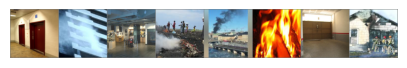

In [21]:
images, labels = next(iter(train_data_loader))

def image_display(image, title=None):

    image = image / 2 + 0.5
    numpy_image = image.numpy()

    numpy_image = np.transpose(
        numpy_image, (1, 2, 0)
    )

    plt.figure(figsize=(5, 5))
    plt.imshow(numpy_image)
    plt.axis("off")

    if title:
        plt.title(title)

    plt.show()

image_display(
    torchvision.utils.make_grid(images[:8])
)

Create ResNet50 model

In [22]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Model = models.resnet50(weights=None)

Model.fc = nn.Linear(
    Model.fc.in_features,
    3
)

Model = Model.to(device)

Device: cuda


Define loss and optimizer

In [23]:
learning_rate = 0.001

criteria = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    Model.parameters(),
    lr=learning_rate
)

scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[10, 15],
    gamma=0.1
)

Train the model

In [24]:
n_epochs = 20

training_loss_array = []
testing_loss_array = []

training_accuracy_array = []
testing_accuracy_array = []

best_accuracy = 0

for epoch in range(n_epochs):

    Model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for data, target in train_data_loader:

        data = data.to(device)
        target = target.to(device)

        optimizer.zero_grad()

        predictions = Model(data)

        loss = criteria(predictions, target)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        predicted = predictions.argmax(dim=1)

        train_total += target.size(0)
        train_correct += (predicted == target).sum().item()

    scheduler.step()

    Model.eval()

    test_loss = 0
    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for data, target in test_data_loader:

            data = data.to(device)
            target = target.to(device)

            predictions = Model(data)

            loss = criteria(predictions, target)

            test_loss += loss.item()

            predicted = predictions.argmax(dim=1)

            test_total += target.size(0)
            test_correct += (predicted == target).sum().item()

    train_acc = 100 * train_correct / train_total
    test_acc = 100 * test_correct / test_total

    training_loss_array.append(
        train_loss / len(train_data_loader)
    )

    testing_loss_array.append(
        test_loss / len(test_data_loader)
    )

    training_accuracy_array.append(train_acc)
    testing_accuracy_array.append(test_acc)

    print(
        f"Epoch {epoch+1}/{n_epochs} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

    if test_acc > best_accuracy:

        best_accuracy = test_acc

        torch.save(
            Model.state_dict(),
            "/content/fire-flame-best.pth"
        )

print("Best recorded accuracy:", best_accuracy)

Epoch 1/20 | Train Accuracy: 70.33% | Test Accuracy: 64.67%
Epoch 2/20 | Train Accuracy: 79.81% | Test Accuracy: 77.33%
Epoch 3/20 | Train Accuracy: 83.04% | Test Accuracy: 77.00%
Epoch 4/20 | Train Accuracy: 83.19% | Test Accuracy: 77.33%
Epoch 5/20 | Train Accuracy: 85.11% | Test Accuracy: 78.00%
Epoch 6/20 | Train Accuracy: 87.52% | Test Accuracy: 75.67%
Epoch 7/20 | Train Accuracy: 87.11% | Test Accuracy: 79.00%
Epoch 8/20 | Train Accuracy: 87.96% | Test Accuracy: 71.33%
Epoch 9/20 | Train Accuracy: 79.96% | Test Accuracy: 76.67%
Epoch 10/20 | Train Accuracy: 85.07% | Test Accuracy: 80.67%
Epoch 11/20 | Train Accuracy: 88.63% | Test Accuracy: 80.33%
Epoch 12/20 | Train Accuracy: 91.04% | Test Accuracy: 81.33%
Epoch 13/20 | Train Accuracy: 93.00% | Test Accuracy: 80.67%
Epoch 14/20 | Train Accuracy: 93.41% | Test Accuracy: 82.00%
Epoch 15/20 | Train Accuracy: 94.00% | Test Accuracy: 82.00%
Epoch 16/20 | Train Accuracy: 96.30% | Test Accuracy: 82.00%
Epoch 17/20 | Train Accuracy: 96.

Plot training and testing accuracy

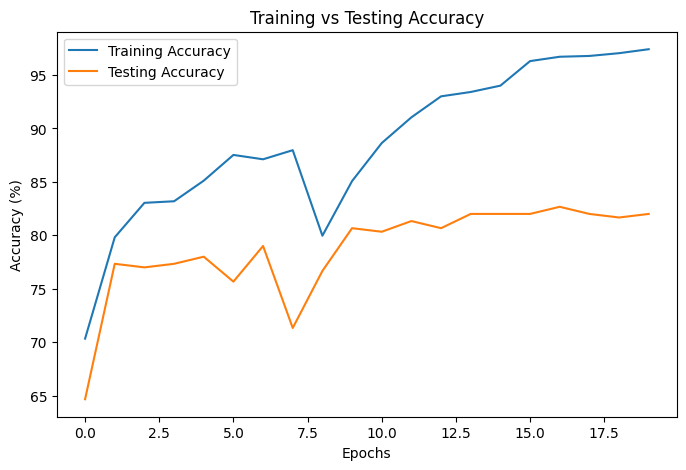

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    training_accuracy_array,
    label="Training Accuracy"
)

plt.plot(
    testing_accuracy_array,
    label="Testing Accuracy"
)

plt.title("Training vs Testing Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

Plot loss graph

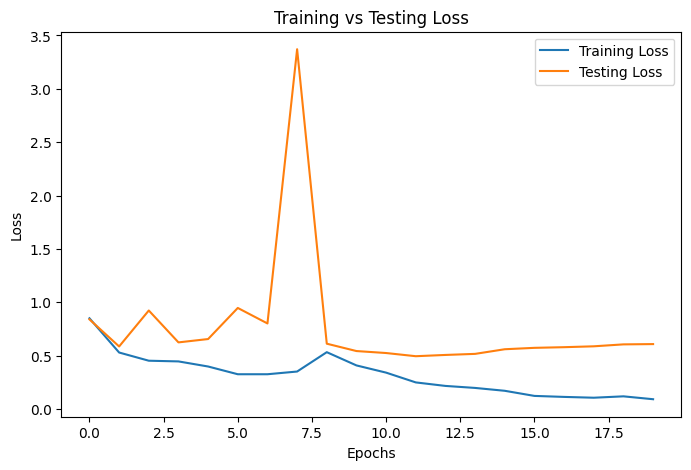

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    training_loss_array,
    label="Training Loss"
)

plt.plot(
    testing_loss_array,
    label="Testing Loss"
)

plt.title("Training vs Testing Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

Confusion matrix

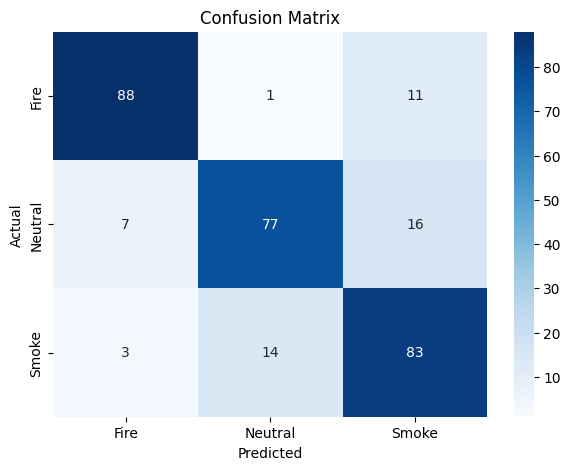

In [27]:
Model.load_state_dict(
    torch.load(
        "/content/fire-flame-best.pth",
        map_location=device
    )
)

Model.eval()

actual = []
predicted_labels = []

with torch.no_grad():

    for images, labels in test_data_loader:

        images = images.to(device)

        outputs = Model(images)

        predictions = outputs.argmax(dim=1)

        actual.extend(labels.numpy())
        predicted_labels.extend(
            predictions.cpu().numpy()
        )

cm = confusion_matrix(
    actual,
    predicted_labels
)

plt.figure(figsize=(7, 5))

import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_data.classes,
    yticklabels=train_data.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Classification report

In [28]:
print(
    classification_report(
        actual,
        predicted_labels,
        target_names=train_data.classes
    )
)

              precision    recall  f1-score   support

        Fire       0.90      0.88      0.89       100
     Neutral       0.84      0.77      0.80       100
       Smoke       0.75      0.83      0.79       100

    accuracy                           0.83       300
   macro avg       0.83      0.83      0.83       300
weighted avg       0.83      0.83      0.83       300



Upload an image for prediction

Saving 47995649-c925-4d27-8268-d0bbda2491b1.png to 47995649-c925-4d27-8268-d0bbda2491b1.png


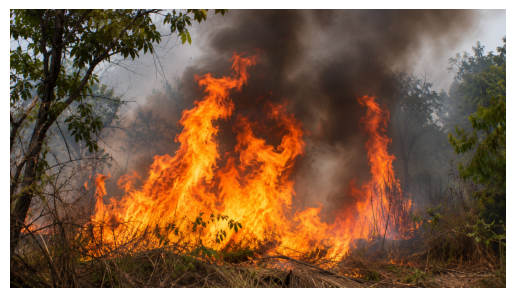

In [29]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

img = Image.open(image_path).convert("RGB")

plt.imshow(img)
plt.axis("off")
plt.show()

Predict Fire, Smoke or Neutral

In [30]:
transformer = transforms.Compose([
    transforms.Resize(225),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

img_processed = transformer(img).unsqueeze(0)

img_processed = img_processed.to(device)

Model.eval()

with torch.no_grad():

    output = Model(img_processed)

    probabilities = torch.softmax(output, dim=1)

    confidence, predicted = probabilities.max(dim=1)

    class_name = train_data.classes[predicted.item()]

print("Prediction:", class_name)

print(
    "Confidence:",
    round(confidence.item() * 100, 2),
    "%"
)

Prediction: Fire
Confidence: 100.0 %


Save the trained model

In [31]:
torch.save(
    Model.state_dict(),
    "/content/Fire_Smoke_ResNet50.pth"
)

files.download(
    "/content/Fire_Smoke_ResNet50.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EfficientNetB0

Create the model

In [32]:
import torch
import torch.nn as nn
from torchvision import models

EfficientNet = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

EfficientNet.classifier[1] = nn.Linear(
    EfficientNet.classifier[1].in_features,
    3
)

EfficientNet = EfficientNet.to(device)

print(EfficientNet)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 94.1MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

Define loss and optimizer

In [33]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    EfficientNet.parameters(),
    lr=0.0001
)

Train EfficientNetB0

In [34]:
epochs = 20

efficientnet_train_acc = []
efficientnet_test_acc = []

for epoch in range(epochs):

    EfficientNet.train()

    correct = 0
    total = 0

    for images, labels in train_data_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = EfficientNet(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = 100 * correct / total

    EfficientNet.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = EfficientNet(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_acc = 100 * correct / total

    efficientnet_train_acc.append(train_acc)
    efficientnet_test_acc.append(test_acc)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Train Accuracy: {train_acc:.2f}% "
        f"Test Accuracy: {test_acc:.2f}%"
    )

torch.save(
    EfficientNet.state_dict(),
    "/content/EfficientNetB0.pth"
)

Epoch 1/20 Train Accuracy: 81.48% Test Accuracy: 94.00%
Epoch 2/20 Train Accuracy: 96.07% Test Accuracy: 95.67%
Epoch 3/20 Train Accuracy: 97.63% Test Accuracy: 95.67%
Epoch 4/20 Train Accuracy: 98.81% Test Accuracy: 96.67%
Epoch 5/20 Train Accuracy: 99.52% Test Accuracy: 96.33%
Epoch 6/20 Train Accuracy: 99.44% Test Accuracy: 95.33%
Epoch 7/20 Train Accuracy: 99.59% Test Accuracy: 96.00%
Epoch 8/20 Train Accuracy: 99.59% Test Accuracy: 96.00%
Epoch 9/20 Train Accuracy: 99.67% Test Accuracy: 95.67%
Epoch 10/20 Train Accuracy: 99.74% Test Accuracy: 96.33%
Epoch 11/20 Train Accuracy: 99.81% Test Accuracy: 96.67%
Epoch 12/20 Train Accuracy: 99.56% Test Accuracy: 97.00%
Epoch 13/20 Train Accuracy: 99.59% Test Accuracy: 95.67%
Epoch 14/20 Train Accuracy: 99.78% Test Accuracy: 95.33%
Epoch 15/20 Train Accuracy: 99.67% Test Accuracy: 96.00%
Epoch 16/20 Train Accuracy: 99.89% Test Accuracy: 97.00%
Epoch 17/20 Train Accuracy: 99.89% Test Accuracy: 97.00%
Epoch 18/20 Train Accuracy: 99.96% Test 

MobileNetV2

In [35]:
MobileNet = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

MobileNet.classifier[1] = nn.Linear(
    MobileNet.classifier[1].in_features,
    3
)

MobileNet = MobileNet.to(device)

print(MobileNet)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 105MB/s] 

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

Define loss and optimizer

In [36]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    MobileNet.parameters(),
    lr=0.0001
)

Train MobileNetV2

In [37]:
epochs = 20

mobilenet_train_acc = []
mobilenet_test_acc = []

for epoch in range(epochs):

    MobileNet.train()

    correct = 0
    total = 0

    for images, labels in train_data_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = MobileNet(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = 100 * correct / total

    MobileNet.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = MobileNet(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_acc = 100 * correct / total

    mobilenet_train_acc.append(train_acc)
    mobilenet_test_acc.append(test_acc)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Train Accuracy: {train_acc:.2f}% "
        f"Test Accuracy: {test_acc:.2f}%"
    )

torch.save(
    MobileNet.state_dict(),
    "/content/MobileNetV2.pth"
)

Epoch 1/20 Train Accuracy: 80.22% Test Accuracy: 90.00%
Epoch 2/20 Train Accuracy: 95.52% Test Accuracy: 94.67%
Epoch 3/20 Train Accuracy: 98.00% Test Accuracy: 96.33%
Epoch 4/20 Train Accuracy: 98.89% Test Accuracy: 96.33%
Epoch 5/20 Train Accuracy: 99.30% Test Accuracy: 96.00%
Epoch 6/20 Train Accuracy: 99.63% Test Accuracy: 96.00%
Epoch 7/20 Train Accuracy: 99.70% Test Accuracy: 96.00%
Epoch 8/20 Train Accuracy: 99.78% Test Accuracy: 96.00%
Epoch 9/20 Train Accuracy: 99.89% Test Accuracy: 97.00%
Epoch 10/20 Train Accuracy: 99.93% Test Accuracy: 96.00%
Epoch 11/20 Train Accuracy: 99.81% Test Accuracy: 96.00%
Epoch 12/20 Train Accuracy: 99.63% Test Accuracy: 95.33%
Epoch 13/20 Train Accuracy: 99.85% Test Accuracy: 96.00%
Epoch 14/20 Train Accuracy: 99.96% Test Accuracy: 95.67%
Epoch 15/20 Train Accuracy: 99.89% Test Accuracy: 95.67%
Epoch 16/20 Train Accuracy: 99.96% Test Accuracy: 95.67%
Epoch 17/20 Train Accuracy: 99.93% Test Accuracy: 95.67%
Epoch 18/20 Train Accuracy: 100.00% Test

Compare all three models

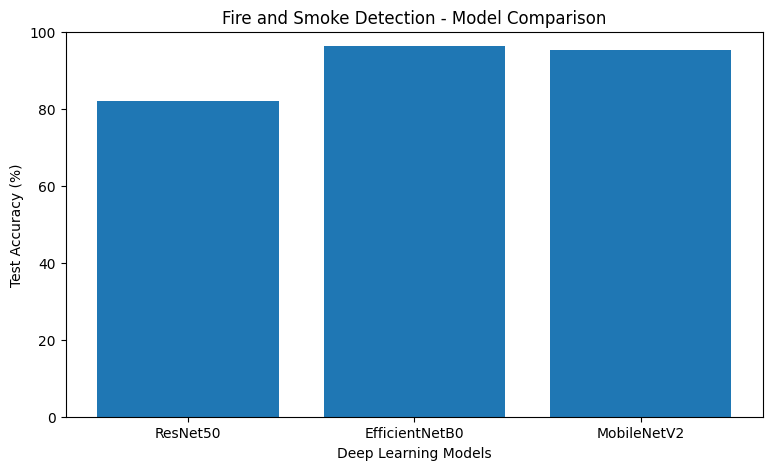

ResNet50 : 82.0 %
EfficientNetB0 : 96.33 %
MobileNetV2 : 95.33 %


In [38]:
model_names = [
    "ResNet50",
    "EfficientNetB0",
    "MobileNetV2"
]

accuracies = [
    testing_accuracy_array[-1],
    efficientnet_test_acc[-1],
    mobilenet_test_acc[-1]
]

plt.figure(figsize=(9, 5))

plt.bar(model_names, accuracies)

plt.title("Fire and Smoke Detection - Model Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 100)

plt.show()

for name, accuracy in zip(model_names, accuracies):
    print(name, ":", round(accuracy, 2), "%")

Plot accuracy comparison

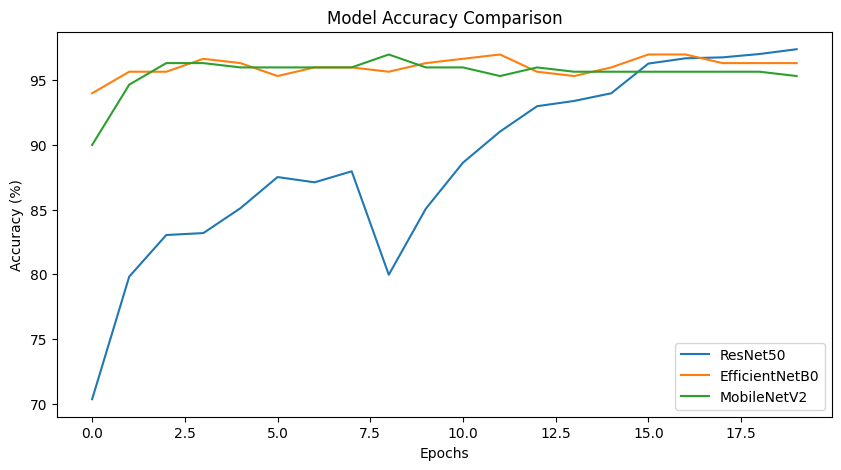

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(
    training_accuracy_array,
    label="ResNet50"
)

plt.plot(
    efficientnet_test_acc,
    label="EfficientNetB0"
)

plt.plot(
    mobilenet_test_acc,
    label="MobileNetV2"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.show()

. Accuracy comparison graph

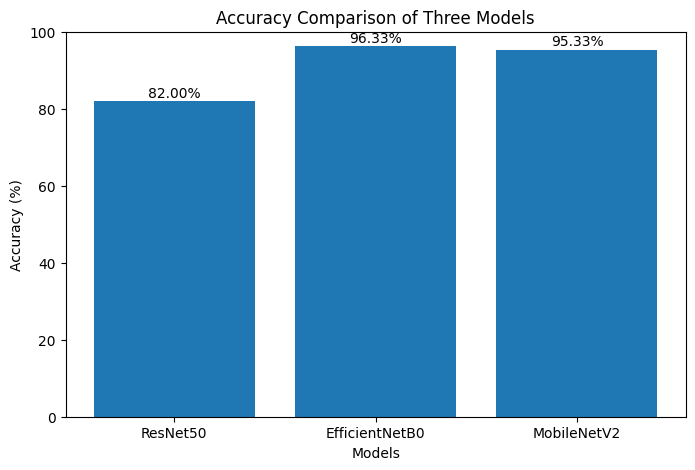

In [40]:
import matplotlib.pyplot as plt

model_names = ["ResNet50", "EfficientNetB0", "MobileNetV2"]

accuracies = [
    testing_accuracy_array[-1],
    efficientnet_test_acc[-1],
    mobilenet_test_acc[-1]
]

plt.figure(figsize=(8, 5))
plt.bar(model_names, accuracies)

plt.title("Accuracy Comparison of Three Models")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

ResNet50 accuracy graph

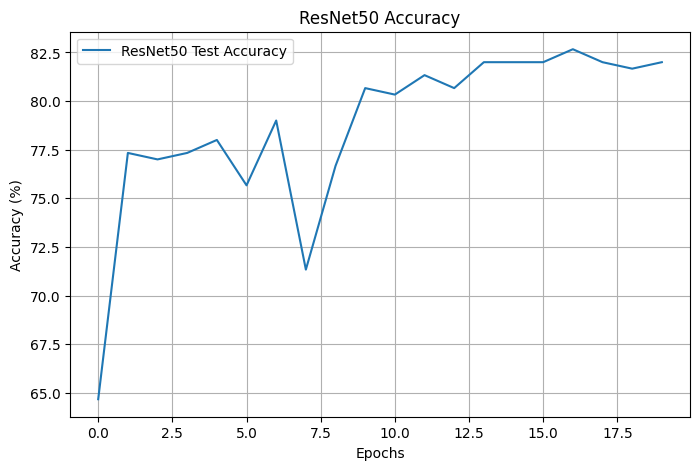

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(testing_accuracy_array, label="ResNet50 Test Accuracy")

plt.title("ResNet50 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.show()

EfficientNetB0 accuracy graph

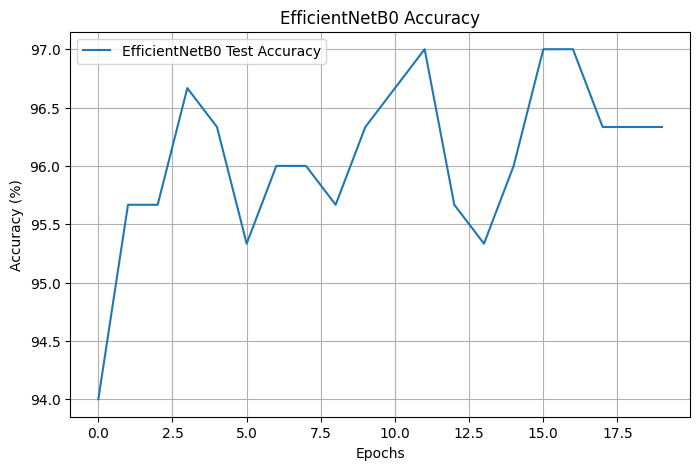

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(efficientnet_test_acc, label="EfficientNetB0 Test Accuracy")

plt.title("EfficientNetB0 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.show()

MobileNetV2 accuracy graph

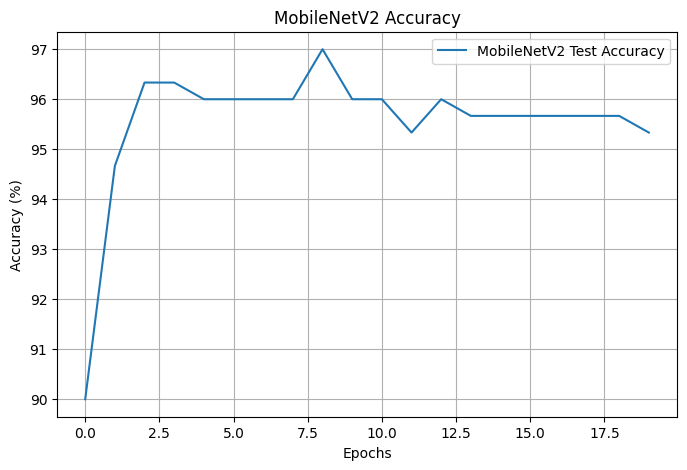

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(mobilenet_test_acc, label="MobileNetV2 Test Accuracy")

plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.show()

Training accuracy comparison

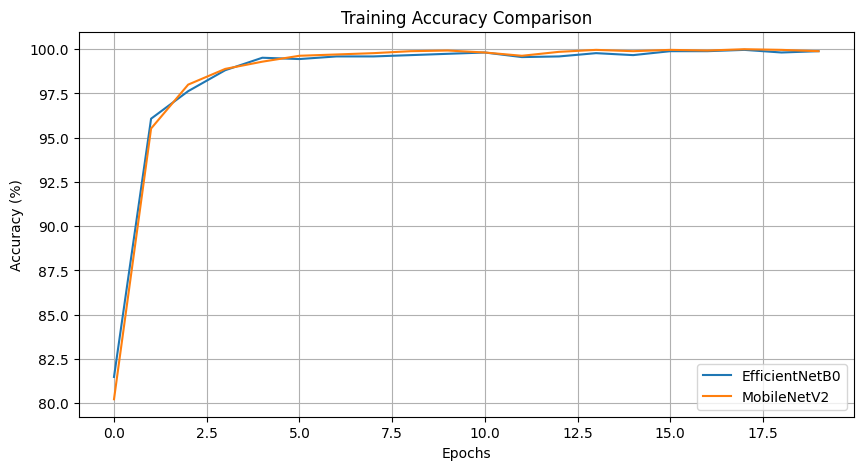

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(efficientnet_train_acc, label="EfficientNetB0")
plt.plot(mobilenet_train_acc, label="MobileNetV2")

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid()
plt.show()

Confusion matrix

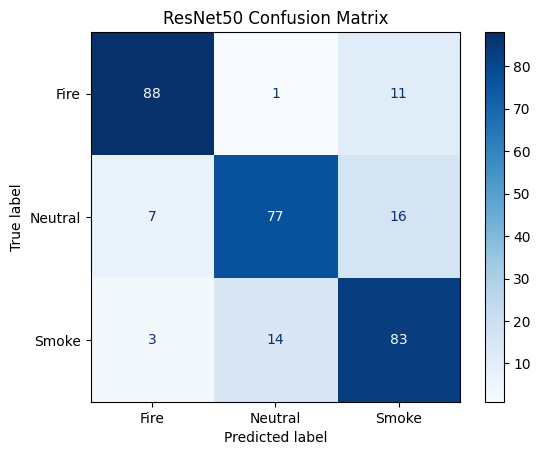

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import torch

Model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_data_loader:
        images = images.to(device)

        outputs = Model(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_data.classes
)

display.plot(cmap="Blues")
plt.title("ResNet50 Confusion Matrix")
plt.show()

Classification report

In [46]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=train_data.classes
))

              precision    recall  f1-score   support

        Fire       0.90      0.88      0.89       100
     Neutral       0.84      0.77      0.80       100
       Smoke       0.75      0.83      0.79       100

    accuracy                           0.83       300
   macro avg       0.83      0.83      0.83       300
weighted avg       0.83      0.83      0.83       300



ROC Curve – All Three Models

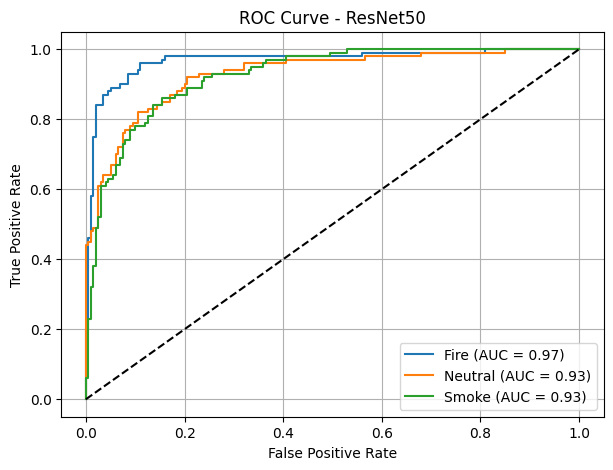

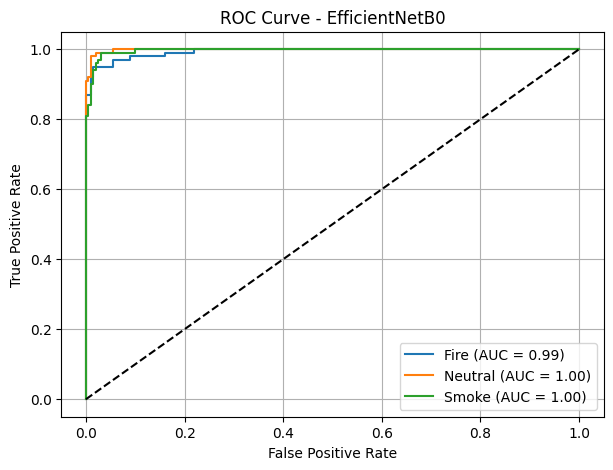

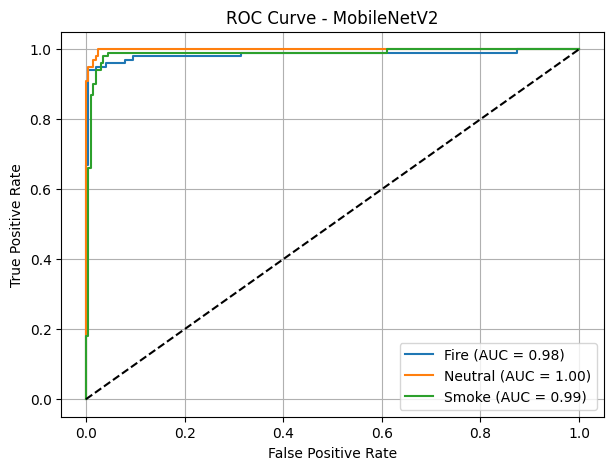

In [47]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

def get_predictions(model, test_loader):
    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            all_labels.extend(labels.numpy())
            all_probs.extend(probabilities.cpu().numpy())

    return np.array(all_labels), np.array(all_probs)


def plot_roc(model, name, test_loader):
    y_true, y_prob = get_predictions(model, test_loader)

    classes = np.arange(len(train_data.classes))
    y_true_bin = label_binarize(y_true, classes=classes)

    plt.figure(figsize=(7, 5))

    for i, class_name in enumerate(train_data.classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr, tpr,
            label=f"{class_name} (AUC = {roc_auc:.2f})"
        )

    plt.plot([0, 1], [0, 1], "k--")

    plt.title(f"ROC Curve - {name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid()
    plt.show()


# ResNet50
plot_roc(Model, "ResNet50", test_data_loader)

# EfficientNetB0
plot_roc(EfficientNet, "EfficientNetB0", test_data_loader)

# MobileNetV2
plot_roc(MobileNet, "MobileNetV2", test_data_loader)